# D502 Capstone Project - Jon Taylor

### Analysis of CDC pertussis incidence data

In [68]:
from pathlib import Path 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from scipy import stats 

file_path = Path('NNDSS_Annual_Summary_Data_2016-2023_Pertussis.csv')

if not file_path.exists():
    raise FileNotFoundError(f"CSV file not found: {file_path.resolve()}")

df = pd.read_csv(file_path)

print('Dataset shape: ', df.shape)
display(df.head())
df.info()

Dataset shape:  (599, 10)


,Notes,Disease,Disease Code,Year,Year Code,Regions/States,Regions/States Code,Case Count,Population for Published Rate,Published Rate
0,NaN,Pertussis,10190.0,2016.0,2016.0,United States,U.S.,17972,323127513,5.56
1,NaN,Pertussis,10190.0,2016.0,2016.0,New England,REGION1,998,14735525,6.77
2,NaN,Pertussis,10190.0,2016.0,2016.0,Connecticut,09,96,3576452,2.68
3,NaN,Pertussis,10190.0,2016.0,2016.0,Maine,23,259,1331479,19.45
4,NaN,Pertussis,10190.0,2016.0,2016.0,Massachusetts,25,202,6811779,2.97


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 599 entries, 0 to 598
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Notes                          47 non-null     object 
 1   Disease                        552 non-null    object 
 2   Disease Code                   552 non-null    float64
 3   Year                           552 non-null    float64
 4   Year Code                      552 non-null    float64
 5   Regions/States                 552 non-null    object 
 6   Regions/States Code            552 non-null    object 
 7   Case Count                     552 non-null    object 
 8   Population for Published Rate  552 non-null    object 
 9   Published Rate                 552 non-null    object 
dtypes: float64(3), object(7)
memory usage: 46.9+ KB


In [69]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values by column:")
display(df.isna().sum().to_frame("Missing values"))

print("\nRows by year:")
display(df.groupby("Year", dropna=False).size().to_frame("Rows"))

print("\nLast 15 rows:")
display(df.tail(15))

Column names:
['Notes', 'Disease', 'Disease Code', 'Year', 'Year Code', 'Regions/States', 'Regions/States Code', 'Case Count', 'Population for Published Rate', 'Published Rate']

Missing values by column:


,Missing values
Notes,552
Disease,47
Disease Code,47
Year,47
Year Code,47
Regions/States,47
Regions/States Code,47
Case Count,47
Population for Published Rate,47
Published Rate,47



Rows by year:


,Rows
Year,
2016.0,69
2017.0,69
2018.0,69
2019.0,69
2020.0,69
2021.0,69
2022.0,69
2023.0,69
NaN,47



Last 15 rows:


,Notes,Disease,Disease Code,Year,Year Code,Regions/States,Regions/States Code,Case Count,Population for Published Rate,Published Rate
584,"(e.g. combining, subsetting, and retirement of...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
585,http://wonder.cdc.gov/wonder/help/nndss.html#R...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
586,"5. Acknowledgment: CDC acknowledges the local,...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
587,case ascertainment sources (e.g. healthcare pr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
588,Notifiable Diseases Surveillance System.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
589,6. Population estimates for calculating incide...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590,the most recent series of estimates available ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
591,with the number of live births in the reportin...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
592,http://wonder.cdc.gov/wonder/help/nndss.html#P...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
593,7. When the national frequency of a disease is...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [70]:

# Keep rows that contain actual data, excluding the CDC documentation notes.
data = df.dropna(subset=["Year"]).copy()

# Remove columns that contain no values
data = data.dropna(axis=1, how='all')

# Convert numeric columns before performing any calculations.
numeric_cols = [
    "Year",
    "Case Count",
    "Population for Published Rate",
    "Published Rate"
]

for col in numeric_cols:
    data[col] = pd.to_numeric(data[col], errors="coerce")

area_col = "Regions/States"

# Identify the two separate New York reporting areas.
ny_labels = [
    "New York (excluding New York City)",
    "New York City"
]

ny = data[data[area_col].isin(ny_labels)].copy()

# Verify that both New York records exist for every year.
ny_check = ny.groupby("Year")[area_col].agg(list)

assert len(ny_check) == 8, "Expected New York data for all eight years."
assert all(len(areas) == 2 for areas in ny_check), (
    "Expected two New York reporting areas per year."
)
assert ny["Case Count"].notna().all()
assert ny["Population for Published Rate"].notna().all()

# Combine case counts and populations, then recalculate incidence rate.
ny_combined = (
    ny.groupby("Year", as_index=False)
      .agg({
          "Case Count": "sum",
          "Population for Published Rate": "sum"
      })
)

ny_combined["Published Rate"] = (
    ny_combined["Case Count"]
    / ny_combined["Population for Published Rate"]
    * 100_000
)

ny_combined[area_col] = "New York"

# Remove the separate New York records and insert the combined records.
data = data[~data[area_col].isin(ny_labels)].copy()
data = pd.concat([data, ny_combined], ignore_index=True)

# Retain only the 50 states and District of Columbia.
us_states_and_dc = {
    "Alabama", "Alaska", "Arizona", "Arkansas", "California",
    "Colorado", "Connecticut", "Delaware", "District of Columbia",
    "Florida", "Georgia", "Hawaii", "Idaho", "Illinois", "Indiana",
    "Iowa", "Kansas", "Kentucky", "Louisiana", "Maine", "Maryland",
    "Massachusetts", "Michigan", "Minnesota", "Mississippi",
    "Missouri", "Montana", "Nebraska", "Nevada", "New Hampshire",
    "New Jersey", "New Mexico", "New York", "North Carolina",
    "North Dakota", "Ohio", "Oklahoma", "Oregon", "Pennsylvania",
    "Rhode Island", "South Carolina", "South Dakota", "Tennessee",
    "Texas", "Utah", "Vermont", "Virginia", "Washington",
    "West Virginia", "Wisconsin", "Wyoming"
}

data[area_col] = data[area_col].str.strip()
data = data[data[area_col].isin(us_states_and_dc)].copy()

# Validate jurisdiction coverage and record uniqueness.
assert data[area_col].nunique() == 51
assert not data.duplicated(subset=["Year", area_col]).any()
assert (data.groupby("Year")[area_col].nunique() == 51).all()

print("Final dataset shape:", data.shape)
print("Jurisdictions:", data[area_col].nunique())
print("Years:", sorted(data["Year"].astype(int).unique()))

print("\nCombined New York records:")
display(
    data.loc[
        data[area_col] == "New York",
        ["Year", "Case Count",
         "Population for Published Rate", "Published Rate"]
    ].sort_values("Year")
)


Final dataset shape: (408, 9)
Jurisdictions: 51
Years: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]

Combined New York records:


,Year,Case Count,Population for Published Rate,Published Rate
536,2016.0,967.0,19745289.0,4.897371
537,2017.0,691.0,19849399.0,3.481214
538,2018.0,558.0,19542209.0,2.855358
539,2019.0,981.0,19453561.0,5.042779
540,2020.0,217.0,19336776.0,1.122214
541,2021.0,147.0,19336776.0,0.760209
542,2022.0,319.0,19677151.0,1.621170
543,2023.0,1012.0,19571216.0,5.170859


In [71]:
# Find state-year records with missing published rates.
missing_rates = data[data["Published Rate"].isna()]

display(
    missing_rates[
        [
            "Year",
            "Regions/States",
            "Case Count",
            "Population for Published Rate",
            "Published Rate"
        ]
    ].sort_values(["Regions/States", "Year"])
)

print("Records with missing rates:", len(missing_rates))

,Year,Regions/States,Case Count,Population for Published Rate,Published Rate
440,2022.0,Mississippi,0.0,2940057.0,NaN
341,2021.0,Rhode Island,0.0,1057125.0,NaN
408,2022.0,Rhode Island,0.0,1093734.0,NaN
342,2021.0,Vermont,0.0,623347.0,NaN
388,2021.0,Wyoming,0.0,582328.0,NaN
522,2023.0,Wyoming,0.0,584057.0,NaN


Records with missing rates: 6


In [72]:
# Fill missing rates only when the case count is zero
# and the population is known and positive.
zero_case_mask = (
    data["Published Rate"].isna()
    & data["Case Count"].eq(0)
    & data["Population for Published Rate"].gt(0)
)

data.loc[zero_case_mask, "Published Rate"] = 0.0

print("Rates filled:", zero_case_mask.sum())
print("Rates still missing:", data["Published Rate"].isna().sum())

# Display any unresolved records.
display(
    data.loc[
        data["Published Rate"].isna(),
        [
            "Year",
            "Regions/States",
            "Case Count",
            "Population for Published Rate",
            "Published Rate"
        ]
    ]
)

Rates filled: 6
Rates still missing: 0


,Year,Regions/States,Case Count,Population for Published Rate,Published Rate


In [73]:
assert data["Regions/States"].nunique() == 51
assert not data.duplicated(
    subset=["Year", "Regions/States"]
).any()
assert (data.groupby("Year")["Regions/States"].nunique() == 51).all()
assert data["Published Rate"].notna().all()

print("Final dataset shape:", data.shape)
print("Validation passed.")

Final dataset shape: (408, 9)
Validation passed.


In [74]:
# Save validated dataframe as CSV
output_path = Path('cleaned_pertussis_data.csv')

data.to_csv(output_path, index=False)

print(f"Cleaned dataset saved to: {output_path.resolve()}")
print(f"Cleaned dataset columns: {data.columns.tolist()}")

Cleaned dataset saved to: /home/jon_taylor/WGU/D502_Capstone/cleaned_pertussis_data.csv
Cleaned dataset columns: ['Disease', 'Disease Code', 'Year', 'Year Code', 'Regions/States', 'Regions/States Code', 'Case Count', 'Population for Published Rate', 'Published Rate']


In [75]:

# Define the two comparison periods.
pre_years = [2016, 2017, 2018, 2019]
post_years = [2022, 2023]

# Calculate each jurisdiction's mean annual incidence rate per period.
pre = (
    data[data["Year"].isin(pre_years)]
    .groupby("Regions/States")["Published Rate"]
    .mean()
    .rename("Pre_Mean_Rate")
)

post = (
    data[data["Year"].isin(post_years)]
    .groupby("Regions/States")["Published Rate"]
    .mean()
    .rename("Post_Mean_Rate")
)

# Combine the two period averages into one comparison table.
comparison = pd.concat([pre, post], axis=1)

# Calculate change: later period minus pre-pandemic period.
comparison["Difference"] = (
    comparison["Post_Mean_Rate"] - comparison["Pre_Mean_Rate"]
)

# Validate that all 51 jurisdictions have both period averages.
assert comparison.shape[0] == 51
assert comparison.notna().all().all()

print("Jurisdictions compared:", len(comparison))
print("\nOverall mean of jurisdiction-level averages:")
print(f"Pre-pandemic: {comparison['Pre_Mean_Rate'].mean():.3f}")
print(f"Later period: {comparison['Post_Mean_Rate'].mean():.3f}")
print(f"Mean paired difference: {comparison['Difference'].mean():.3f}")

print("\nJurisdictions with lower later-period rates:",
      (comparison["Difference"] < 0).sum())
print("Jurisdictions with higher later-period rates:",
      (comparison["Difference"] > 0).sum())
print("Jurisdictions with no change:",
      (comparison["Difference"] == 0).sum())

display(comparison.sort_values("Difference"))


Jurisdictions compared: 51

Overall mean of jurisdiction-level averages:
Pre-pandemic: 6.680
Later period: 1.457
Mean paired difference: -5.223

Jurisdictions with lower later-period rates: 50
Jurisdictions with higher later-period rates: 1
Jurisdictions with no change: 0


,Pre_Mean_Rate,Post_Mean_Rate,Difference
Regions/States,,,
Maine,27.98750,5.575000,-22.412500
Vermont,19.01750,0.230000,-18.787500
Montana,17.96750,2.210000,-15.757500
Wisconsin,14.79000,0.600000,-14.190000
Minnesota,11.70500,0.830000,-10.875000
Idaho,11.69500,1.095000,-10.600000
Alaska,11.97750,1.910000,-10.067500
Washington,8.66000,1.045000,-7.615000
Oregon,8.13000,0.670000,-7.460000


In [76]:

# Paired differences: later-period mean minus pre-pandemic mean.
differences = comparison["Difference"]

# 1. Test normality of the paired differences.
shapiro_result = stats.shapiro(differences)

# 2. Paired t-test on the jurisdiction-level period means.
ttest_result = stats.ttest_rel(
    comparison["Post_Mean_Rate"],
    comparison["Pre_Mean_Rate"]
)

# 3. Wilcoxon signed-rank test.
wilcoxon_result = stats.wilcoxon(
    comparison["Post_Mean_Rate"],
    comparison["Pre_Mean_Rate"],
    alternative="two-sided"
)

# 4. Exact binomial sign test.
n_decreased = (differences < 0).sum()
n_increased = (differences > 0).sum()

sign_result = stats.binomtest(
    n_decreased,
    n=n_decreased + n_increased,
    p=0.5,
    alternative="two-sided"
)

# 5. 95% confidence interval for the mean paired difference.
n = len(differences)
mean_diff = differences.mean()
sd_diff = differences.std(ddof=1)
se_diff = sd_diff / np.sqrt(n)
critical_t = stats.t.ppf(0.975, df=n - 1)

ci_low = mean_diff - critical_t * se_diff
ci_high = mean_diff + critical_t * se_diff

# 6. Cohen's dz effect size for paired observations.
cohens_dz = mean_diff / sd_diff

print("SHAPIRO-WILK NORMALITY TEST")
print(f"W = {shapiro_result.statistic:.4f}, "
      f"p = {shapiro_result.pvalue:.6g}")

print("\nPAIRED T-TEST")
print(f"t({n - 1}) = {ttest_result.statistic:.4f}, "
      f"p = {ttest_result.pvalue:.6g}")

print("\nWILCOXON SIGNED-RANK TEST")
print(f"Statistic = {wilcoxon_result.statistic:.4f}, "
      f"p = {wilcoxon_result.pvalue:.6g}")

print("\nEXACT SIGN TEST")
print(f"Decreases = {n_decreased}, increases = {n_increased}")
print(f"p = {sign_result.pvalue:.6g}")

print("\n95% CONFIDENCE INTERVAL FOR MEAN PAIRED DIFFERENCE")
print(f"Mean difference = {mean_diff:.4f}")
print(f"95% CI = [{ci_low:.4f}, {ci_high:.4f}]")

print("\nCOHEN'S dz")
print(f"d = {cohens_dz:.4f}")


SHAPIRO-WILK NORMALITY TEST
W = 0.8112, p = 1.32835e-06

PAIRED T-TEST
t(50) = -8.1410, p = 1.00738e-10

WILCOXON SIGNED-RANK TEST
Statistic = 1.0000, p = 5.46152e-10

EXACT SIGN TEST
Decreases = 50, increases = 1
p = 4.61853e-14

95% CONFIDENCE INTERVAL FOR MEAN PAIRED DIFFERENCE
Mean difference = -5.2232
95% CI = [-6.5119, -3.9345]

COHEN'S dz
d = -1.1400


| Measure                                                  | Result             |
| :------------------------------------------------------- | -----------------: |
| Jurisdictions                                            |                 51 |
| Pre-period mean incidence rate                           |  6.680 per 100,000 |
| Later-period mean incidence rate                         |  1.457 per 100,000 |
| Mean paired difference                                   | −5.223 per 100,000 |
| Decrease in unweighted means of jurisdiction-level rates |              78.2% |
| 95% CI for mean paired difference                        |   [-6.512, -3.935] |
| Cohen's dz                                               |             -1.140 |
| Jurisdictions with a decrease                            |           50 of 51 |
| Jurisdiction with an increase                            |             Nevada |

Paired t-test

p = 1.00738e-10

Reject the null hypothesis at alpha = 0.05. The mean jurisdiction-level incidence rate differed significantly between the two periods.

Wilcoxon signed-rank test

p = 5.46152e-10

Reject the null under the test's assumptions. The paired differences also show a statistically significant rank-based shift.

Exact sign test

p = 4.61853e-14

Reject the null of equally likely increases and decreases. Fifty jurisdictions decreased and one slightly increased.

Shapiro-Wilk normality test

p = 1.32835e-06

Reject normality of the paired differences. Interpret the paired t-test and its confidence interval with this limitation in mind. The Wilcoxon and sign tests provide complementary evidence of a difference between the periods.

In [77]:

# Confirm the number of observations per jurisdiction in each period.
pre_counts = (
    data[data["Year"].isin(pre_years)]
    .groupby("Regions/States")["Year"]
    .nunique()
)

post_counts = (
    data[data["Year"].isin(post_years)]
    .groupby("Regions/States")["Year"]
    .nunique()
)

print("Pre-period observations per jurisdiction:")
display(pre_counts.value_counts().sort_index())

print("\nLater-period observations per jurisdiction:")
display(post_counts.value_counts().sort_index())

# Verify the expected number of years for every jurisdiction.
assert (pre_counts == 4).all()
assert (post_counts == 2).all()

print("\nYear-count validation passed.")

# Display the five largest decreases and increases.
print("\nLargest decreases:")
display(comparison.nsmallest(5, "Difference"))

print("\nLargest increases:")
display(comparison.nlargest(5, "Difference"))


Pre-period observations per jurisdiction:


Year
4    51
Name: count, dtype: int64


Later-period observations per jurisdiction:


Year
2    51
Name: count, dtype: int64


Year-count validation passed.

Largest decreases:


,Pre_Mean_Rate,Post_Mean_Rate,Difference
Regions/States,,,
Maine,27.9875,5.575,-22.4125
Vermont,19.0175,0.230,-18.7875
Montana,17.9675,2.210,-15.7575
Wisconsin,14.7900,0.600,-14.1900
Minnesota,11.7050,0.830,-10.8750



Largest increases:


,Pre_Mean_Rate,Post_Mean_Rate,Difference
Regions/States,,,
Nevada,2.38750,2.530000,0.142500
West Virginia,1.45500,1.185000,-0.270000
New York,4.06918,3.396014,-0.673166
Mississippi,1.15500,0.050000,-1.105000
Florida,1.67000,0.325000,-1.345000


### Visualizations

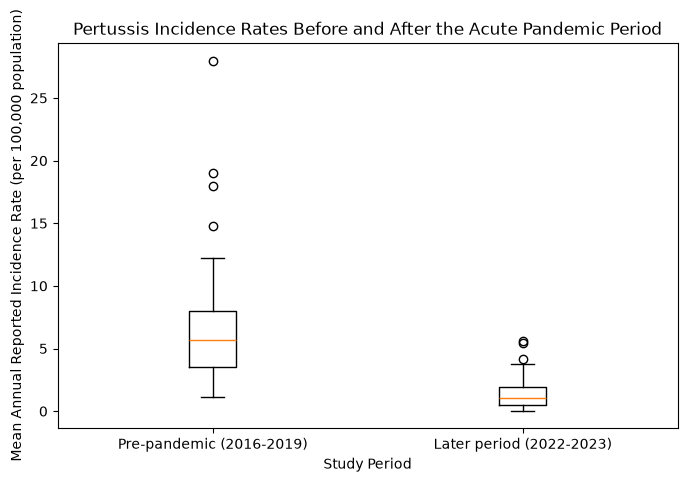

In [78]:
plt.figure(figsize=(8,5))

plt.boxplot(
    [
        comparison["Pre_Mean_Rate"],
        comparison["Post_Mean_Rate"]
    ],
    tick_labels=['Pre-pandemic (2016-2019)', 'Later period (2022-2023)']
)

plt.title("Pertussis Incidence Rates Before and After the Acute Pandemic Period")
plt.ylabel("Mean Annual Reported Incidence Rate (per 100,000 population)")
plt.xlabel("Study Period")

plt.show()

Figure 1. Distribution of jurisdiction-level mean annual reported pertussis incidence rates for the pre-pandemic period (2016–2019) and later period (2022–2023). Each box represents the distribution of mean rates across the 51 jurisdictions. The later period shows a lower median and less variability in reported incidence.

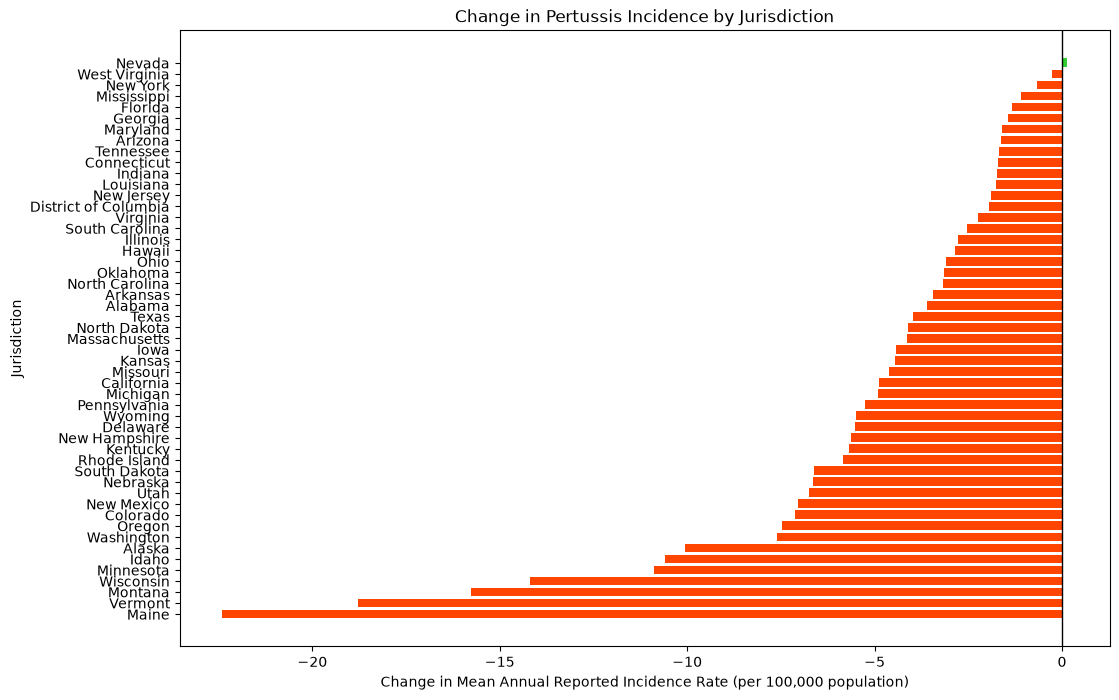

In [79]:
differences = comparison["Difference"].sort_values()

bar_colors = [
    "orangered" if value < 0 else "limegreen"
    for value in differences.values
]

plt.figure(figsize=(12, 8))

plt.barh(differences.index, differences.values, color=bar_colors)
plt.axvline(0, color="black", linewidth=1)
plt.title("Change in Pertussis Incidence by Jurisdiction")
plt.xlabel("Change in Mean Annual Reported Incidence Rate (per 100,000 population)")
plt.ylabel("Jurisdiction")
plt.show()

Figure 2. Change in Pertussis Incidence by Jurisdiction. Bars show the difference between each jurisdiction's 2022 - 2023 and 2016 - 2019 average annual incidemce rates. Negative values indicate decreases; positive values indicate increases. Fifty jurisdictions had lower average rates in the later period, while one had a slight increase.

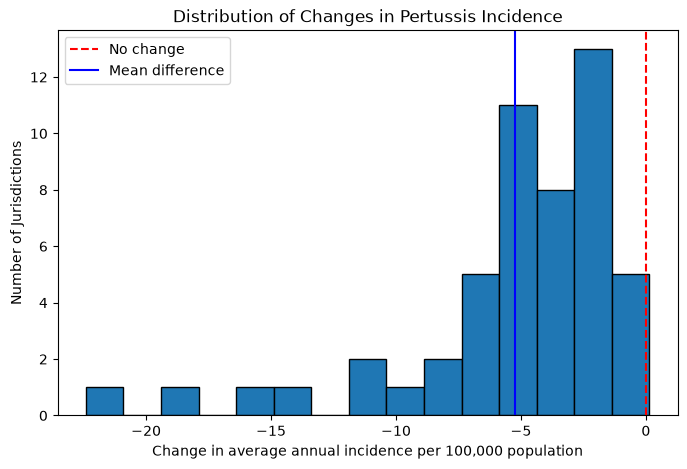

In [80]:
plt.figure(figsize=(8, 5))

plt.hist(comparison['Difference'], bins=15, edgecolor='black')
plt.axvline(0, color='red', linestyle='--', label='No change')
plt.axvline(
    comparison["Difference"].mean(),
    color='blue',
    linestyle='-',
    label='Mean difference'
)

plt.title("Distribution of Changes in Pertussis Incidence")
plt.xlabel("Change in average annual incidence per 100,000 population")
plt.ylabel("Number of Jurisdictions")
plt.legend()
plt.show()

Figure 3. Distribution of Changes in Pertussis Incidence. The histogram displays jurisdiction-level differences in average incidence rates, calculated as later-period average minus the pre-pandemic average. Most differences are negative, with a long tail toward larger decreases. Reference lines indicate zero change and the mean difference. 